# 惑星運動のベイズモデル — ODE と多峰性に立ち向かうワークフロー (PyMC 版)

このノートブックは、Bayesian Workflow 論文 (Gelman et al. 2020, [arXiv:2011.01808](https://arxiv.org/abs/2011.01808)) の付録で扱われている惑星運動の例を、**公式の Stan ケーススタディに準拠して PyMC で再実装**したものです。

- 原典: Charles C. Margossian and Andrew Gelman,
  ["Bayesian Model of Planetary Motion: exploring ideas for a modeling workflow when dealing with ordinary differential equations and multimodality"](https://mc-stan.org/learn-stan/case-studies/planetary_motion.html)
- 公式ソース (Rmd + Stan): [stan-dev/example-models/knitr/planetary_motion](https://github.com/stan-dev/example-models/tree/master/knitr/planetary_motion)

**ストーリー**: 惑星の位置の時系列観測から、星と惑星の系の物理量(重力、初期位置、初期運動量、恒星の位置)を推定します。
一見単純な ODE モデルですが、ベイズ推定を行うと**予期しない多峰性**が現れ、チェーンが混合せず、推定が信頼できなくなります。
チェーンが初期値を忘れてくれないとき、どうするか?
計算統計と物理の両方から推論して、モードの発生機構を診断し、推定を修復していく過程を追体験します。

## ワークフローの流れ

1. **モデル構築** — ハミルトン形式の運動方程式 + 正規観測誤差
2. **データのシミュレーション** — 既知の真値からデータを生成(シミュレーションベースの検証)
3. **完全モデルのフィットが大失敗** → **単純化モデル**($k$ のみ推定)へ後退
4. **診断** — $\widehat R$、トレースプロット、チェーン別の事後予測チェック
5. **多峰性の解剖** — 対数結合密度のグリッド計算、軌道の可視化、モードの発生機構の理解
6. **推定の改善** — 事前分布 vs 再重み付け vs **初期値の調整**
7. **モデルを組み戻す** — $(k) \to (k, p_0, q_0, q_*)$、事前分布の設計、条件付き尤度による診断

## Stan 版との実装上の違い(重要)

原典は Stan の適応刻み幅の ODE ソルバー (`integrate_ode_rk45` / `integrate_ode_bdf`、許容誤差 1e-6) を使います。
PyMC には同等の微分可能な適応ソルバーが無いため、本ノートブックでは
**固定刻み幅の 4 次 Runge-Kutta (RK4) を `pytensor.scan` で実装**し、JAX にコンパイルして NUTS(numpyro)で勾配ごとサンプリングします。

この違いは「悪いチェーンの症状」に現れます:

- **Stan (適応ソルバー)**: $k$ が大きいと軌道の変化が速くなり、同じ精度を保つためソルバーが刻みを細かくして**劇的に遅くなる**(原典で「悪いチェーンは 1000 倍遅い」と報告される現象)
- **本実装 (固定刻み RK4)**: 計算時間は一定のまま、$k$ が大きい領域で**精度が落ちる**

「決定論的には簡単な問題が、ベイズ推定ではパラメータ空間の思わぬ領域で難問になる」という原典の教訓は、
どちらの実装でも(症状を変えて)現れます。積分器の精度検証もワークフローの一部として実施します。

In [1]:
import os
# この Windows 環境には 64bit C++ コンパイラが無いため、PyTensor の C バックエンドを無効化する。
# NUTS のサンプリング(勾配計算を含む)は JAX (numpyro) 経由で JIT コンパイルされる。
os.environ.setdefault("PYTENSOR_FLAGS", "cxx=")

import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="pytensor")
warnings.filterwarnings("ignore", category=FutureWarning)

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy import stats

import pymc as pm
import pytensor
import pytensor.tensor as pt
import arviz as az
from pymc.sampling.jax import sample_jax_nuts

RANDOM_SEED = 1954  # 原典の set.seed(1954) に合わせる
rng = np.random.default_rng(RANDOM_SEED)
plt.rcParams["figure.figsize"] = (7, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print(f"PyMC {pm.__version__} / ArviZ {az.__version__} / NumPy {np.__version__}")

PyMC 6.0.1 / ArviZ 1.2.0 / NumPy 2.4.6


## 1. モデルの構築

星と惑星の単純な系を考えます。星は惑星よりはるかに重く、位置は**固定**と近似します。推定したい量:

- **重力の強さ**: 重力定数 $G = 10^{-3}$ は既知とし、惑星質量を $m = 1$ に固定。太陽質量 $M$ を評価したい。実際に扱うのは $k = GmM$
- 惑星の**初期位置** $q_0$ と**初期運動量** $p_0$
- 恒星の位置 $q_*$

### 運動方程式

ニュートンの運動方程式(2 階 ODE)をハミルトン形式(1 階 ODE の系)で書きます:

$$
\frac{\mathrm{d}q}{\mathrm{d}t} = \frac{p}{m}, \qquad
\frac{\mathrm{d}p}{\mathrm{d}t} = -\frac{k}{r^3}(q - q_*)
$$

ここで $k = GmM$、$r = \sqrt{(q-q_*)^\top (q-q_*)}$ は惑星と星の距離。観測は正規誤差つき:

$$
q_{\rm obs} \sim \mathrm{Normal}(q,\ \sigma I), \quad \sigma = 0.01
$$

## 2. データのシミュレーション

原典 (`planetary_motion_sim.stan`) と同じ設定でデータを生成します:
$t=0$ で $q_0 = (1, 0)$、$p_0 = (0, 1)$、$k = 1$、$m = 1$、観測時刻 $t_i = i/10\ (i=1,\dots,40)$。

Stan 版は `integrate_ode_rk45` で「真の」軌道を計算します。ここでは scipy の適応ソルバー
(`solve_ivp`、許容誤差 1e-10)を使います。真値既知のシミュレーションデータでモデルを検証するのは、
ワークフローの推奨ステップ(fake-data simulation)です。

> ちなみに $|q_0|=1$、$|p_0|=1$、$k=1$ はちょうど円軌道(周期 $2\pi$)になる設定です。観測窓 $t \le 4$ は
> 1 周期の約 3 分の 2 に相当します。

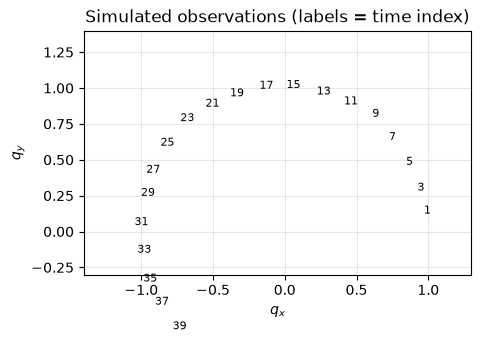

In [2]:
n_obs = 40
sigma_obs = 0.01
ts = np.arange(1, n_obs + 1) / 10  # t = 0.1, ..., 4.0
k_true, m_true = 1.0, 1.0
q0_true = np.array([1.0, 0.0])
p0_true = np.array([0.0, 1.0])


def hamilton_rhs(t, yv, k, star):
    """ハミルトン方程式の右辺。yv = [qx, qy, px, py]。"""
    q, p = yv[:2], yv[2:]
    d = q - star
    r3 = np.sum(d**2) ** 1.5
    return np.concatenate([p / m_true, -k * d / r3])


sol = solve_ivp(hamilton_rhs, (0, ts[-1]), np.concatenate([q0_true, p0_true]),
                t_eval=ts, args=(k_true, np.zeros(2)), rtol=1e-10, atol=1e-10)
q_true = sol.y[:2].T                      # (40, 2) 真の軌道
q_obs = q_true + rng.normal(0, sigma_obs, q_true.shape)  # 観測 (正規誤差つき)

fig, ax = plt.subplots(figsize=(5, 4.2))
for i in range(0, n_obs, 2):
    ax.text(q_obs[i, 0], q_obs[i, 1], str(i + 1), fontsize=8, ha="center")
ax.set_xlim(-1.4, 1.3); ax.set_ylim(-0.3, 1.4)
ax.set_xlabel("$q_x$"); ax.set_ylabel("$q_y$")
ax.set_title("Simulated observations (labels = time index)")
ax.set_aspect("equal")
plt.show()

## 3. PyMC における ODE の実装と検証

### 3.1 固定刻み RK4 (モデル内で使用)

Stan の `integrate_ode_rk45` に対応する部分を、`pytensor.scan` による固定刻み RK4 で実装します。
刻み幅 $\Delta t = 0.01$、400 ステップで $t = 4$ まで積分し、10 ステップごと(= 観測時刻)の状態を取り出します。
`scan` は JAX の `lax.scan` にコンパイルされ、自動微分で勾配も得られます(Stan の感度方程式に相当する役割を
リバースモード自動微分が担います)。

### 3.2 リープフロッグ (グリッド計算用、原典 tools.r の移植)

原典はモードの探索やグリッド計算に、`tools.r` の `solve_trajectory`(リープフロッグ法、$\Delta t = 0.001$)
を使っています。これを numpy に移植し、パラメータのバッチに対してベクトル化します。

### 3.3 積分器の検証 (ワークフロー補足)

**推定に使う数値解法そのものの検証**もワークフローの一部です。RK4 の解を scipy の高精度解と比較し、
誤差が観測ノイズ $\sigma = 0.01$ より十分小さいことを確認します。さらに、$k$ を大きくしたときに
固定刻み RK4 の誤差がどう成長するかも見ておきます(後で「悪いチェーン」の議論に効いてきます)。

In [3]:
DT = 0.01          # RK4 の刻み幅
N_STEPS = 400      # 400 * 0.01 = 4.0 = 最終観測時刻
THIN = 10          # 10 ステップごとに観測時刻 (0.1 刻み) が来る


def make_rk4_trajectory(k, q0, p0, star):
    """pytensor で RK4 により軌道を解き、観測時刻の位置 (40, 2) を返す。

    k: スカラー, q0/p0/star: 長さ 2 のテンソル。
    Stan の integrate_ode_rk45(ode, y0, t0, ts, theta, ...) に相当する。
    """
    y0 = pt.concatenate([q0, p0])

    def deriv(y, k_, star_):
        q, p = y[:2], y[2:]
        d = q - star_
        r3 = pt.sum(d**2) ** 1.5
        return pt.concatenate([p / m_true, -k_ * d / r3])

    def rk4_step(y, k_, star_):
        k1 = deriv(y, k_, star_)
        k2 = deriv(y + DT / 2 * k1, k_, star_)
        k3 = deriv(y + DT / 2 * k2, k_, star_)
        k4 = deriv(y + DT * k3, k_, star_)
        return y + DT / 6 * (k1 + 2 * k2 + 2 * k3 + k4)

    # 重要: k や star (確率変数) はクロージャで捕まえず non_sequences で明示的に渡す
    ys, _ = pytensor.scan(rk4_step, outputs_info=y0,
                          non_sequences=[k, star], n_steps=N_STEPS)
    return ys[THIN - 1::THIN][:, :2]  # 観測時刻 t = 0.1, ..., 4.0 の位置

In [4]:
def solve_trajectory_batch(k, q0, p0, star=None, dt=0.001, ts=ts):
    """原典 tools.r の solve_trajectory (リープフロッグ) の numpy 移植・バッチ版。

    k: (B,), q0/p0/star: (B, 2)。戻り値 (B, n_obs, 2)。
    """
    k = np.atleast_1d(np.asarray(k, float))
    B = k.shape[0]
    q = np.broadcast_to(np.asarray(q0, float), (B, 2)).copy()
    p = np.broadcast_to(np.asarray(p0, float), (B, 2)).copy()
    star = np.zeros((B, 2)) if star is None else np.broadcast_to(np.asarray(star, float), (B, 2))

    def dp_dt(q):
        d = q - star
        r3 = np.sum(d**2, axis=1, keepdims=True) ** 1.5
        return -k[:, None] * d / r3

    record_every = int(round(ts[0] / dt))  # 100 ステップごとに観測時刻
    n_steps = int(round(ts[-1] / dt))
    out = np.empty((B, len(ts), 2))
    j = 0
    for step in range(1, n_steps + 1):
        p = p + 0.5 * dt * dp_dt(q)
        q = q + p / m_true * dt
        p = p + 0.5 * dt * dp_dt(q)
        if step % record_every == 0:
            out[:, j] = q
            j += 1
    return out

In [5]:
# --- 積分器の検証 ---
# (1) pytensor RK4 vs scipy 高精度解 (k=1)
k_ = pt.dscalar("k")
traj_pt = make_rk4_trajectory(k_, pt.as_tensor(q0_true), pt.as_tensor(p0_true),
                              pt.as_tensor(np.zeros(2)))
traj_fn = pytensor.function([k_], traj_pt)
err_rk4 = np.abs(traj_fn(1.0) - q_true).max()

# (2) リープフロッグ (dt=0.001) vs scipy 高精度解 (k=1)
err_leap = np.abs(solve_trajectory_batch([1.0], q0_true, p0_true)[0] - q_true).max()
print(f"max |RK4(dt=0.01) - scipy(tol=1e-10)|      = {err_rk4:.2e}")
print(f"max |leapfrog(dt=0.001) - scipy(tol=1e-10)| = {err_leap:.2e}")
print(f"観測ノイズ sigma = {sigma_obs}  → どちらも十分小さい")

# (3) k を大きくしたときの RK4 誤差の成長
print("\nk が大きいときの RK4(dt=0.01) の誤差:")
for k_test in [1.0, 3.0, 5.0, 7.0]:
    sol_k = solve_ivp(hamilton_rhs, (0, ts[-1]), np.concatenate([q0_true, p0_true]),
                      t_eval=ts, args=(k_test, np.zeros(2)), rtol=1e-10, atol=1e-10)
    err_k = np.abs(traj_fn(k_test) - sol_k.y[:2].T).max()
    print(f"  k = {k_test:.1f}: max error = {err_k:.2e}")

C:\Users\nwl6h\AppData\Local\Temp\ipykernel_282052\3227148719.py:28: DeprecationWarning: Scan return signature will change. Updates dict will not be returned, only the first argument. Pass `return_updates=False` to conform to the new API and avoid this warning
  ys, _ = pytensor.scan(rk4_step, outputs_info=y0,


max |RK4(dt=0.01) - scipy(tol=1e-10)|      = 6.78e-10
max |leapfrog(dt=0.001) - scipy(tol=1e-10)| = 1.57e-06
観測ノイズ sigma = 0.01  → どちらも十分小さい

k が大きいときの RK4(dt=0.01) の誤差:
  k = 1.0: max error = 6.78e-10
  k = 3.0: max error = 1.45e-03
  k = 5.0: max error = 8.79e-01


  k = 7.0: max error = 5.61e+01


$k = 1$ 付近では RK4 の誤差は観測ノイズより桁違いに小さく、推定には十分です。
一方 $k$ が大きくなると誤差が急速に成長します。Stan の適応ソルバーなら精度を保つ代わりに**遅く**なる領域で、
固定刻みソルバーは速いまま**不正確**になる — 同じ困難の別の顔です。
幸い、後で見るようにこの領域は事後確率がほぼゼロの「無駄な」領域であり、
問題の本質(多峰性)はどちらの実装でも同じです。

## 4. 単純化モデル: $k$ だけを推定する

完全モデル(7 パラメータ)をいきなりフィットすると盛大に失敗します(原典でも同様)。
そこでワークフローの定石に従い、**単純化したモデル**から始めます。シミュレーションデータなので、
$k$ 以外のパラメータをすべて真値に固定できます。事後分布は

$$
p(k \mid q_{\rm obs}), \qquad k \sim \mathrm{Normal}^+(0, 1)
$$

原典の Stan コード (`planetary_motion.stan`) の要点:

```stan
transformed data {
  array[2] real q0 = {1.0, 0.0};
  array[2] real p0 = {0.0, 1.0};
  real m = 1.0;
  real<lower=0> sigma_x = 0.01;
  real<lower=0> sigma_y = 0.01;
}
parameters {
  real<lower=0> k;
}
transformed parameters {
  array[n, 4] real y = integrate_ode_bdf(ode, y0, t0, t, {k}, {m}, x_i, ...);
}
model {
  k ~ normal(0, 1);
  q_obs[:, 1] ~ normal(y[:, 1], sigma_x);
  q_obs[:, 2] ~ normal(y[:, 2], sigma_y);
}
generated quantities {
  array[n] real qx_pred = normal_rng(y[:, 1], sigma_x);
  array[n] real qy_pred = normal_rng(y[:, 2], sigma_y);
}
```

### 初期値の設定 — Stan のデフォルトを再現する

原典の分析の核心は**初期値**にあります。Stan のデフォルト初期値は、非制約空間上の一様分布
$\log k^{(0)} \sim \mathrm{uniform}(-2, 2)$、つまり $k^{(0)} \in (0.135,\ 7.39)$ という広い範囲です。
これを再現するため、チェーンごとに明示的な初期値を与えます(PyMC 側のジッターは切って、初期値を完全に制御します)。

原典と同じく **8 チェーン**、warmup 500 / sampling 500 で回します。

In [6]:
CHAINS = 8


def make_model_k():
    """k のみを推定する単純化モデル。"""
    with pm.Model(coords={"time": ts, "coord": ["x", "y"]}) as model:
        k = pm.HalfNormal("k", 1)  # Stan: real<lower=0> k; k ~ normal(0, 1);
        q = pm.Deterministic(
            "q",
            make_rk4_trajectory(k, pt.as_tensor(q0_true), pt.as_tensor(p0_true),
                                pt.as_tensor(np.zeros(2))),
            dims=("time", "coord"))
        pm.Normal("q_obs", mu=q, sigma=sigma_obs, observed=q_obs, dims=("time", "coord"))
    return model


# Stan のデフォルト初期値を再現: log k0 ~ uniform(-2, 2)
init_rng = np.random.default_rng(RANDOM_SEED)
k_init_wide = np.exp(init_rng.uniform(-2, 2, CHAINS))
print("initial k per chain:", np.round(k_init_wide, 3))

model_k = make_model_k()
t0 = time.time()
idata_k = sample_jax_nuts(
    model=model_k, nuts_sampler="numpyro",
    draws=500, tune=500, chains=CHAINS,
    initvals=[{"k": float(v)} for v in k_init_wide],
    jitter=False, chain_method="vectorized",
    random_seed=RANDOM_SEED, progressbar=False,
)
print(f"sampling took {time.time() - t0:.0f} s")

initial k per chain: [4.64  0.22  3.744 0.634 0.44  2.471 0.756 1.078]


C:\Users\nwl6h\AppData\Local\Temp\ipykernel_282052\3227148719.py:28: DeprecationWarning: Scan return signature will change. Updates dict will not be returned, only the first argument. Pass `return_updates=False` to conform to the new API and avoid this warning
  ys, _ = pytensor.scan(rk4_step, outputs_info=y0,


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


sampling took 16 s


> **実行時間について**: 原典では悪いチェーンが良いチェーンの最大 1000 倍遅い(2 秒 vs 2000 秒)ことが
> 報告されています。適応ソルバーが大きな $k$ で苦しむためです。本実装は固定刻みなので 1 ステップの計算量は
> 一定ですが、`chain_method="vectorized"` では全チェーンが歩調を合わせるため、悪いチェーンの長い NUTS 木
> (max treedepth 到達)が全体を遅くします。「悪いチェーンは統計的に役立たずなだけでなく計算資源も食う」
> という教訓は同じです。

### 4.1 診断: $\widehat R$ とトレースプロット

まず要約統計を見ます。原典と同様、対数事後密度(`lp`、Stan の `lp__` に相当)と $k$ に注目します。

In [7]:
summ = az.summary(idata_k, var_names=["k"])
print(summ[["mean", "sd", "ess_bulk", "ess_tail", "r_hat"]])
n_div = int(idata_k.sample_stats["diverging"].sum())
print(f"\ndivergences: {n_div}")
print(f"R-hat = {float(summ['r_hat'].iloc[0]):.2f}  →  1.01 を桁違いに超えている!")

  mean   sd  ess_bulk  ess_tail r_hat
k    2  1.5        11         9  1.87

divergences: 0
R-hat = 1.87  →  1.01 を桁違いに超えている!


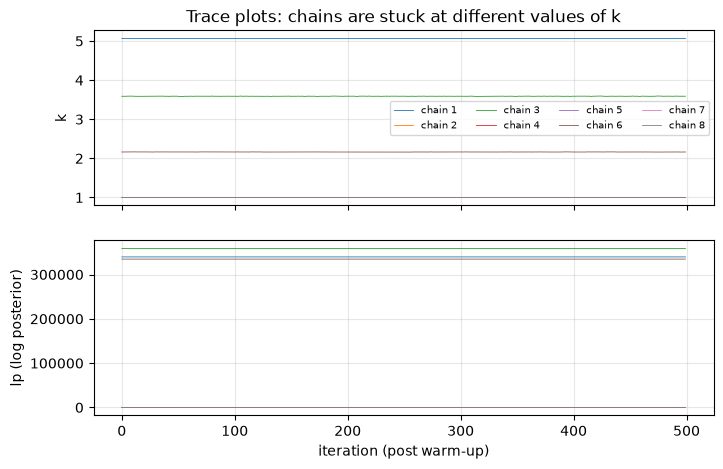

In [8]:
def trace_by_chain(idata, ax_k, ax_lp):
    """k と lp (対数事後密度) のチェーン別トレースプロット。"""
    post_k = idata.posterior["k"].values      # (chains, draws)
    lp = idata.sample_stats["lp"].values
    for c in range(post_k.shape[0]):
        ax_k.plot(post_k[c], lw=0.6, label=f"chain {c+1}")
        ax_lp.plot(lp[c], lw=0.6)
    ax_k.set_ylabel("k"); ax_lp.set_ylabel("lp (log posterior)")
    ax_lp.set_xlabel("iteration (post warm-up)")
    ax_k.legend(ncol=4, fontsize=7)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
trace_by_chain(idata_k, ax1, ax2)
ax1.set_title("Trace plots: chains are stuck at different values of k")
plt.show()

In [9]:
# チェーンごとの初期値・事後平均・lp を並べる:
# 「チェーンの最終位置は初期値でほぼ決まっている」ことの確認
chain_table = pd.DataFrame({
    "initial k": k_init_wide,
    "posterior mean k": idata_k.posterior["k"].mean(dim="draw").values,
    "mean lp": idata_k.sample_stats["lp"].mean(dim="draw").values,
}, index=[f"chain {c+1}" for c in range(CHAINS)])
chain_table.round(3)

,initial k,posterior mean k,mean lp
chain 1,4.640,5.066,339703.471
chain 2,0.220,0.999,-244.798
chain 3,3.744,3.588,358788.690
chain 4,0.634,0.999,-244.791
chain 5,0.440,0.999,-244.799
chain 6,2.471,2.163,334743.024
chain 7,0.756,0.999,-244.813
chain 8,1.078,0.999,-244.770


$\widehat R \gg 1$、チェーンはまったく混合していません。上の表が原典の核心的観察を示しています:

- $k \approx 1$ 付近に落ち着いたチェーンは**高い対数事後密度**を持つ
- 大きな $k$ に留まったチェーンは低い lp のまま動けない
- **チェーンの最終位置は初期値でほぼ決まる** — 原典は warmup を含むトレースプロットから
  「数イテレーションでモードに捕まる」ことを確認しています(numpyro 経由では warmup 標本を保存できないため、
  ここでは初期値との対応表で同じ結論を示しました)

この時点で立てられる仮説(原典 §3):

1. モデルが縮退していて $k$ を識別できない?
2. チェーンが局所モードに捕まっている?
3. 平坦な面で勾配が働かない?
4. 大きな $k$ で数値積分が破綻している?

### 4.2 チェーン別の事後予測チェックで「縮退」仮説を棄却する

もし異なる $k$ が同じデータ生成過程を与える(縮退)なら、どのチェーンも似た予測を出すはずです。
チェーンごとに事後予測軌道(`generated quantities` の `q_pred` に相当)を描いて確かめます。

Stan の `generated quantities` は事後サンプルの決定論的関数なので、ここでは保存済みの
`q`(`Deterministic`)に観測ノイズを足すだけで同じものが得られます(ODE を解き直す必要はありません)。

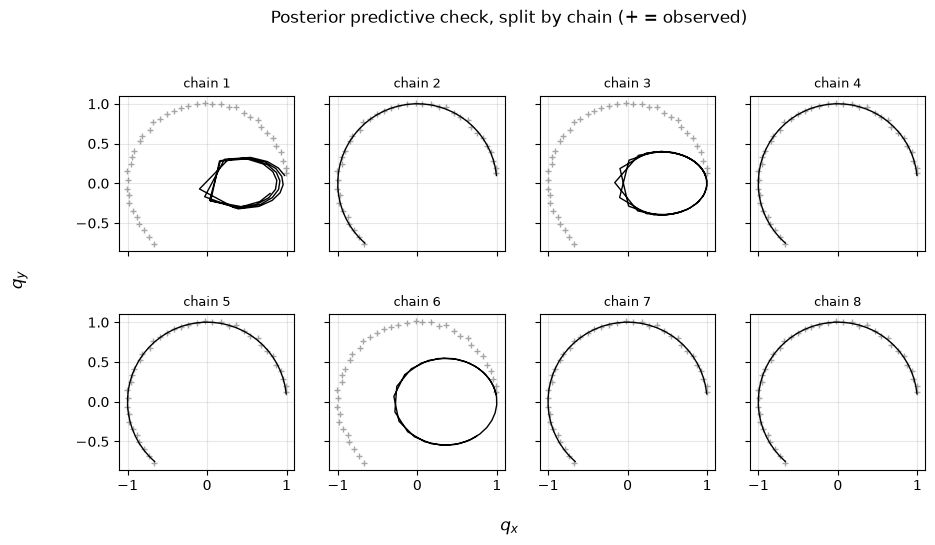

In [10]:
def ppc_plot_2d(idata, q_obs, extra_var=None, ncols=4):
    """原典 tools.r の ppc_plot2D の再現: チェーンごとに事後予測軌道の中央値と観測を重ねる。

    extra_var: 追加で中央値をマーカー表示する変数名 (例: "star")。
    """
    q_post = idata.posterior["q"]  # (chain, draw, time, coord)
    chains = q_post.sizes["chain"]
    nrows = int(np.ceil(chains / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.6 * ncols, 2.6 * nrows),
                             sharex=True, sharey=True)
    for c, ax in zip(range(chains), axes.ravel()):
        # 事後予測 q_pred = q + noise の中央値 ≈ q の中央値 (sigma = 0.01 は微小)
        q_med = q_post.isel(chain=c).median(dim="draw").values
        ax.plot(q_obs[:, 0], q_obs[:, 1], "+", color="gray", ms=5, alpha=0.7)
        ax.plot(q_med[:, 0], q_med[:, 1], "k-", lw=1)
        if extra_var is not None:
            v = idata.posterior[extra_var].isel(chain=c).median(dim="draw").values
            ax.plot(v[0], v[1], "*", color="C1", ms=10)
        ax.set_title(f"chain {c+1}", fontsize=9)
        ax.set_aspect("equal")
    for ax in axes.ravel()[chains:]:
        ax.axis("off")
    fig.supxlabel("$q_x$"); fig.supylabel("$q_y$")
    return fig

fig = ppc_plot_2d(idata_k, q_obs)
fig.suptitle("Posterior predictive check, split by chain (+ = observed)", y=1.02)
plt.show()

$k \approx 1$ に落ちたチェーンだけがデータを再現できています(lp が高いこととも整合)。
チェーンごとに予測がまるで違う → **縮退が原因ではない**。仮説 1 は棄却。
残るは「局所モード」仮説です。ここからは標準的な診断を超えて、**この問題に固有の分析**に踏み込みます。

## 5. 多峰性の解剖

### 5.1 局所モードの存在をグリッド計算で確認する

パラメータが 1 次元なので「ズル」ができます: $k$ のグリッド上で対数結合密度(非正規化事後密度)

$$
\log p(q_{\rm obs}, k) = \sum_i \log \mathrm{normal}(q_{{\rm obs},i} \mid q_i(k), \sigma) + \log \mathrm{normal}^+(k \mid 0, 1)
$$

を直接計算します(原典と同じく、軌道はリープフロッグ $\Delta t = 0.001$ で計算)。

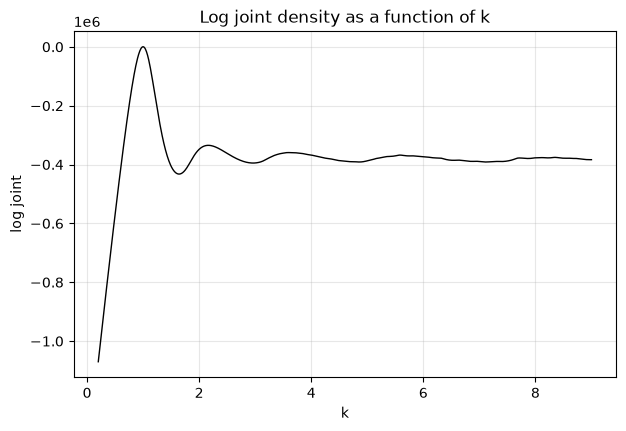

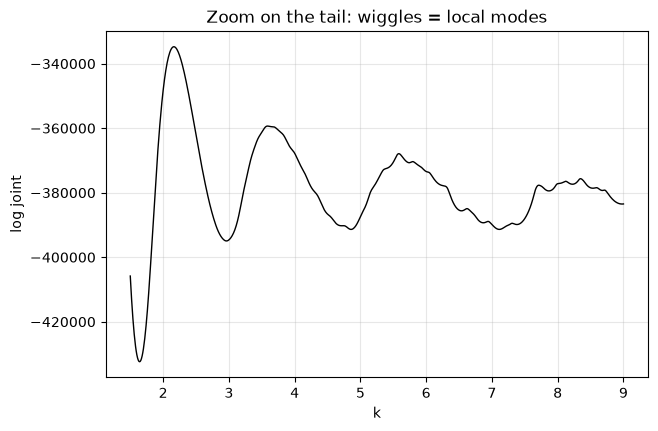

In [11]:
ks_grid = np.arange(0.2, 9.0 + 1e-9, 0.01)
q_sim_grid = solve_trajectory_batch(ks_grid, q0_true, p0_true)  # (K, 40, 2)

log_joint = (
    stats.norm.logpdf(q_obs[None, :, :], q_sim_grid, sigma_obs).sum(axis=(1, 2))
    + stats.norm.logpdf(ks_grid, 0, 1)
)

fig, ax = plt.subplots()
ax.plot(ks_grid, log_joint, "k-", lw=1)
ax.set_xlabel("k"); ax.set_ylabel("log joint")
ax.set_title("Log joint density as a function of k")
plt.show()

# 裾のモードを拡大
fig, ax = plt.subplots()
mask = ks_grid > 1.5
ax.plot(ks_grid[mask], log_joint[mask], "k-", lw=1)
ax.set_xlabel("k"); ax.set_ylabel("log joint")
ax.set_title("Zoom on the tail: wiggles = local modes")
plt.show()

$k = 1$ に鋭い大域モードがあり、それより大きい $k$ には「さざ波」状の**局所モード**が並んでいます。
チェーンが捕まっていた場所の正体です。

### 5.2 楕円運動が多峰性を生む機構

対数尤度は、観測 $q_{\rm obs}$ と $k$ を仮定した軌道 $q(k)$ の距離を罰する関数と読めます:

$$
\log p(q_{\rm obs} \mid k) = C - \frac{1}{2\sigma^2} \lVert q_{\rm obs} - q(k) \rVert_2^2
$$

いろいろな $k$ で軌道を描いてみます(原典の図の再現):

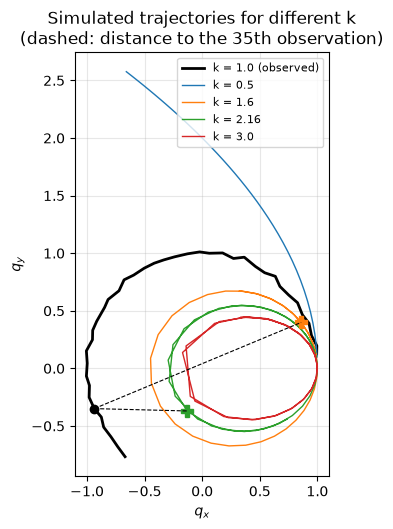

In [12]:
k_show = [0.5, 1.6, 2.16, 3.0]
trajs = solve_trajectory_batch(k_show, q0_true, p0_true)
comp_point = 34  # 原典の 35 番目の観測 (0-index で 34)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.plot(q_obs[:, 0], q_obs[:, 1], "-", color="k", lw=2, label="k = 1.0 (observed)")
for kv, tr, col in zip(k_show, trajs, ["C0", "C1", "C2", "C3"]):
    ax.plot(tr[:, 0], tr[:, 1], "-", color=col, lw=1, label=f"k = {kv}")
# 35 番目の観測と、k=1.6 / k=2.16 の同時刻の位置を結ぶ
ax.plot(*q_obs[comp_point], "ko", ms=6)
for tr, col in zip(trajs[1:3], ["C1", "C2"]):
    ax.plot(*tr[comp_point], marker="P", color=col, ms=8, ls="none")
    ax.plot([q_obs[comp_point, 0], tr[comp_point, 0]],
            [q_obs[comp_point, 1], tr[comp_point, 1]], "k--", lw=0.8)
ax.set_xlabel("$q_x$"); ax.set_ylabel("$q_y$")
ax.set_title("Simulated trajectories for different k\n(dashed: distance to the 35th observation)")
ax.legend(fontsize=8)
ax.set_aspect("equal")
plt.show()

観察(原典 §3.4):

- $k$ が大きいほど重力が強く、軌道が短く(周期が小さく)なる。十分大きい $k$ では観測時間内に**複数周回**する
- $k < 1$ では軌道は観測楕円からいくらでも遠くに離れられる。一方 $k > 1$ の軌道は観測楕円の**内側**に収まるので、距離が有界になる
- $k$ を変えて楕円が「回転」していくと、観測位置とシミュレーション位置が**偶然そろう**瞬間があり、これが尤度の裾のさざ波(局所モード)を作る。
  上の図の 35 番目の観測では、$k = 2.16$ の軌道のほうが $k = 1.6$ より観測に近い!

**局所モードは、周期的観測と正規尤度の相互作用が生む数学的な人工物**であり、興味ある潜在現象ではありません。
また、トレースと対数密度から明らかに、これらのモードの事後確率質量は無視できるほど小さい。
つまり、そこに捕まったチェーンは計算資源の純粋な無駄です。

### 5.3 悪いチェーンはなぜ遅いのか (原典 §3.5 の議論)

Stan では、$k$ が大きいと 1 ステップ $\Delta t$ の間に惑星が長い弧を描くため、適応ソルバーは同じ精度を
保とうと刻みを細かくし、積分が劇的に遅くなります。**「決定論的には簡単な問題が、ベイズ推定では難問になる」**
— 推定はパラメータ空間の広い範囲で ODE を解くことを要求するからです。

理想はアルゴリズムが「速く失敗する」ことですが、現実は逆でした。原典の教訓:
**失敗の診断に 1000 イテレーションも待つ必要はない**。モデル開発の初期段階では短いランで素早く診断すべきです
(この分析は 100 ドローでも可能でした)。

## 6. 推定の改善

候補は 3 つ(原典 §3.6):

1. **より強い事前分布を組む** — 今回は効かない。モードの密度は下がっても裾のさざ波は残るし、MCMC は非正規化密度で
   動くので密度の大きさ自体は探索に影響しない。皮肉なことに、**データを増やすほどさざ波は強くなる**。
   現状の $\mathrm{normal}^+(0,1)$ ですら局所モードの $k$ の値とは矛盾しているのに、チェーンは捕まった
2. **チェーンの再重み付け (stacking)** — 妥当なモンテカルロ推定は得られるが、(i) 8 チェーンで全モードを網羅的に
   探索できたとは言えず、(ii) 遅い悪いチェーンの計算コストは払ったまま
3. **初期値を調整する** — Stan のデフォルト初期値は事前分布(と我々のドメイン知識)に無頓着だった。
   非漸近的な状況ではチェーンは初期値を忘れてくれない。**初期値もアルゴリズムのチューニングパラメータ**であり、
   万能のデフォルトは存在しない

$\widehat R$ による収束判定のためには初期値は事後分布に対して**過分散**であってほしい。しかし分散が大きすぎると
チェーンが妥当な領域に到達できない。ヒューリスティックとしては「事前分布(または少し過分散にした事前分布)から
初期値を引く」が挙げられます。最初の広い初期値でチェーンの挙動を観察した後で、より狭い初期化分布に切り替えることは
正当化できる、というのが原典の立場です。

### 6.1 初期値を直して単純化モデルを再フィット

原典に従い $\log k^{(0)} \sim \mathrm{uniform}(-0.5, 0.5)$ を使います。

In [13]:
k_init_narrow = np.exp(init_rng.uniform(-0.5, 0.5, CHAINS))
print("initial k per chain:", np.round(k_init_narrow, 3))

t0 = time.time()
idata_k2 = sample_jax_nuts(
    model=model_k, nuts_sampler="numpyro",
    draws=500, tune=500, chains=CHAINS,
    initvals=[{"k": float(v)} for v in k_init_narrow],
    jitter=False, chain_method="vectorized",
    random_seed=RANDOM_SEED, progressbar=False,
)
print(f"sampling took {time.time() - t0:.0f} s")

summ2 = az.summary(idata_k2, var_names=["k"])
print(summ2[["mean", "sd", "ess_bulk", "ess_tail", "r_hat"]])
print(f"divergences: {int(idata_k2.sample_stats['diverging'].sum())}")
print(f"true k = {k_true}")

initial k per chain: [1.377 1.075 1.158 1.609 1.444 0.801 1.079 1.355]


sampling took 13 s
     mean       sd  ess_bulk  ess_tail r_hat
k  0.9992  0.00034      1467      1722  1.00
divergences: 0
true k = 1.0


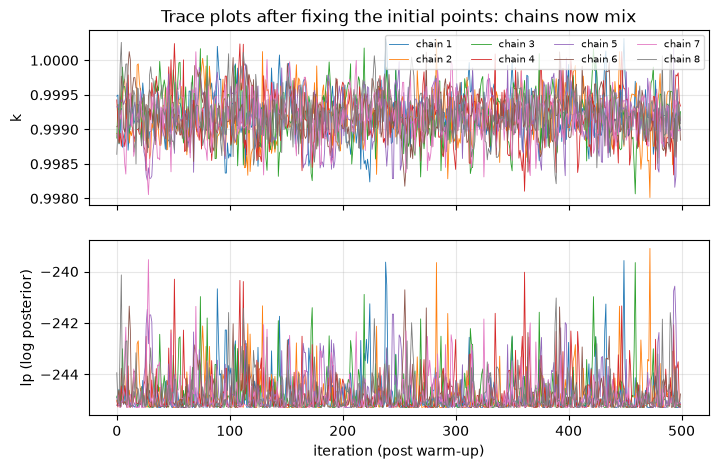

In [14]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
trace_by_chain(idata_k2, ax1, ax2)
ax1.set_title("Trace plots after fixing the initial points: chains now mix")
plt.show()

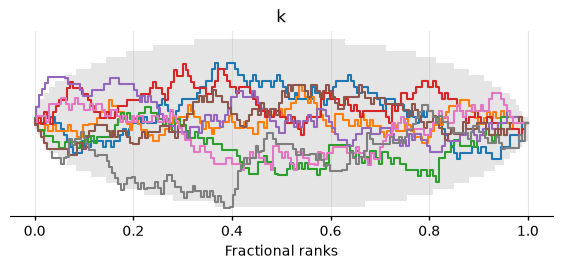

In [15]:
az.plot_rank(idata_k2, var_names=["k"]);

$\widehat R \approx 1$、全チェーンが $k = 1$ 付近に収束し、真値を回復しました。

## 7. モデルを組み戻す: $(k) \to (k, p_0) \to (k, p_0, q_0) \to (k, p_0, q_0, q_*)$

単純化モデルから出発して、パラメータを 1〜2 個ずつ「固定解除」しながら元のモデルへ戻します(原典 §4)。
途中のモデルで遭遇する問題のほとんどは、単純化モデルで理解した
**「尤度と周期的観測の相互作用」**に帰着します。

原典が報告する例($p_0$ を推定に加えたとき): 事前情報のない初期運動量に対して、
$p_0 \approx (-0.5, -1.5)$ —— つまり惑星が**時計回り**に動くモードが見つかります。
十分速く動けば、生成軌道の一部が観測軌道と揃ってしまうのです
(これを発見できたのも事後予測チェックのおかげ、と原典は強調しています)。
対策として、データから作る**粗い経験的推定値**で初期値を導きます:

$$
\hat p = \frac{q_{{\rm obs},2} - q_{{\rm obs},1}}{t_2 - t_1}, \qquad \hat q = q_{{\rm obs},1}
$$

これに摂動を加えて、チェーンごとに異なる初期値を作ります。

## 8. 恒星の位置まで推定するフルモデル

最後に、これまで原点に固定していた恒星の位置 $q_*$ (`star`) も未知として推定します。
ODE の $r$ と力の向きが $q - q_*$ に依存するようになります。

### 8.1 事前分布に情報を込める (原典 §5.1)

星が固定という近似は星が惑星よりずっと重いときのみ有効です。前のモデルでは $q_* = (0,0)$ がこれを強制していましたが、
今度は**事前分布でこの信念を表現**します。モデルに陽に現れない恒星質量 $M$ について太陽系の桁
($M_\odot = 2 \times 10^{30}$ kg、木星質量 $1.9 \times 10^{27}$ kg)から推論すると、
木星型惑星を観測している状況では $M \sim \mathrm{Normal}(10^3, 5 \times 10^2)$(適切な単位系)程度が見込まれ、
$G = 10^{-3}$ より $k = GmM$ の事前分布として

$$
k \sim \mathrm{Normal}(1, 10^{-3})
$$

を得ます(原典コメント曰く「それでもかなり無情報」)。最初に使った $\mathrm{normal}^+(0,1)$ より
はるかに情報的です。**パラメータそのものではなく、その背後の物理量について事前知識を表現してから変換する**
— 事前分布設計の良い実例です。

原典の Stan コード (`planetary_motion_star.stan`) の要点:

```stan
parameters {
  real<lower=0> k;
  array[2] real q0;
  array[2] real p0;
  array[2] real star;
}
model {
  k ~ normal(1, 0.001);
  p0[1] ~ normal(0, 1);
  p0[2] ~ lognormal(0, 1);  // p0 の y 成分は正 (反時計回り) を課す
  q0 ~ normal(0, 1);
  star ~ normal(0, 0.5);
  q_obs[:, 1] ~ normal(y[:, 1], sigma_x);
  q_obs[:, 2] ~ normal(y[:, 2], sigma_y);
}
```

`p0[2] ~ lognormal(0, 1)` に注意 — §7 で見つけた「時計回りモード」を、
**正の $p_{0,y}$ という制約**で排除しています(データを見て惑星は反時計回りと判断できる)。

In [16]:
def make_model_star():
    """フルモデル: k, q0, p0, star を推定。"""
    with pm.Model(coords={"time": ts, "coord": ["x", "y"]}) as model:
        k = pm.TruncatedNormal("k", mu=1, sigma=0.001, lower=0)
        q0 = pm.Normal("q0", 0, 1, dims="coord")
        p0x = pm.Normal("p0x", 0, 1)
        p0y = pm.LogNormal("p0y", 0, 1)  # 反時計回り (p0_y > 0) を課す
        p0 = pm.Deterministic("p0", pt.stack([p0x, p0y]), dims="coord")
        star = pm.Normal("star", 0, 0.5, dims="coord")
        q = pm.Deterministic("q", make_rk4_trajectory(k, q0, p0, star),
                             dims=("time", "coord"))
        pm.Normal("q_obs", mu=q, sigma=sigma_obs, observed=q_obs, dims=("time", "coord"))
    return model


model_star = make_model_star()

C:\Users\nwl6h\AppData\Local\Temp\ipykernel_282052\3227148719.py:28: DeprecationWarning: Scan return signature will change. Updates dict will not be returned, only the first argument. Pass `return_updates=False` to conform to the new API and avoid this warning
  ys, _ = pytensor.scan(rk4_step, outputs_info=y0,


### 8.2 最初のフィット: 経験的初期値 + 広い星位置 (原典 §5.2)

§7 の経験的推定値で $q_0, p_0$ の初期値を作り、星の位置は観測範囲内の広い一様分布から引きます:

- $k^{(0)} = |\mathrm{Normal}(0, 0.5)|$
- $p_0^{(0)} \sim \mathrm{Normal}(\hat p, 0.1)$、$q_0^{(0)} \sim \mathrm{Normal}(\hat q, 0.1)$
- $q_*^{(0)} \sim \mathrm{Uniform}(-1, 1)^2$

In [17]:
p0_empirical = (q_obs[1] - q_obs[0]) / (ts[1] - ts[0])
q0_empirical = q_obs[0]
print(f"empirical p0_hat = {np.round(p0_empirical, 3)}  (true: {p0_true})")
print(f"empirical q0_hat = {np.round(q0_empirical, 3)}  (true: {q0_true})")


def init_empirical(rng, sd=0.1, star_dist="wide"):
    p0_init = rng.normal(p0_empirical, sd)
    p0_init[1] = max(p0_init[1], 0.05)  # p0y は lognormal なので正に保つ
    star_init = (rng.uniform(-1, 1, 2) if star_dist == "wide"
                 else rng.normal(0, 0.5, 2))
    return {
        "k": float(abs(rng.normal(0, 0.5))) + 1e-3,
        "q0": rng.normal(q0_empirical, sd),
        "p0x": float(p0_init[0]),
        "p0y": float(p0_init[1]),
        "star": star_init,
    }


init_rng2 = np.random.default_rng(RANDOM_SEED)
inits_pass1 = [init_empirical(init_rng2, sd=0.1, star_dist="wide") for _ in range(CHAINS)]
pd.DataFrame([{kk: np.round(vv, 3) for kk, vv in d.items()} for d in inits_pass1],
             index=[f"chain {c+1}" for c in range(CHAINS)])

empirical p0_hat = [0.014 0.717]  (true: [0. 1.])
empirical q0_hat = [0.994 0.125]  (true: [1. 0.])


,k,q0,p0x,p0y,star
chain 1,0.312,"[0.885, 0.187]",0.002,0.966,"[0.66, -0.228]"
chain 2,0.267,"[0.853, 0.051]",0.034,0.643,"[0.144, 0.293]"
chain 3,0.109,"[0.881, 0.202]",-0.208,0.661,"[-0.271, 0.632]"
chain 4,0.467,"[1.065, 0.292]",-0.045,0.745,"[-0.288, -0.88]"
chain 5,0.067,"[1.023, 0.006]",-0.079,0.738,"[0.569, 0.464]"
chain 6,0.511,"[0.985, 0.162]",-0.038,0.627,"[-0.214, 0.997]"
chain 7,0.603,"[1.225, 0.277]",0.029,0.783,"[0.621, 0.79]"
chain 8,0.706,"[0.875, -0.057]",-0.002,0.558,"[-0.733, 0.402]"


In [18]:
t0 = time.time()
idata_star1 = sample_jax_nuts(
    model=model_star, nuts_sampler="numpyro",
    draws=500, tune=500, chains=CHAINS,
    initvals=inits_pass1, jitter=False, chain_method="vectorized",
    random_seed=RANDOM_SEED, progressbar=False,
)
print(f"sampling took {time.time() - t0:.0f} s")
print(f"divergences: {int(idata_star1.sample_stats['diverging'].sum())} / {CHAINS * 500}")
print(f"max treedepth hits: {int((idata_star1.sample_stats['tree_depth'] >= 10).sum())}")

pars = ["k", "q0", "p0", "star"]
summ_star1 = az.summary(idata_star1, var_names=pars)
summ_star1[["mean", "sd", "ess_bulk", "ess_tail", "r_hat"]]

sampling took 651 s
divergences: 0 / 4000
max treedepth hits: 0


,mean,sd,ess_bulk,ess_tail,r_hat
k,0.99988,0.00101,4102,2496,1.00
q0[x],1,0.0037,1777,2061,1.00
q0[y],-0.0009,0.0048,1196,1594,1.01
p0[x],0.004,0.0065,1211,1381,1.01
p0[y],1.0026,0.0045,1095,1728,1.01
star[x],0.0022,0.0054,1179,1754,1.01
star[y],0.0069,0.0055,1809,2151,1.00


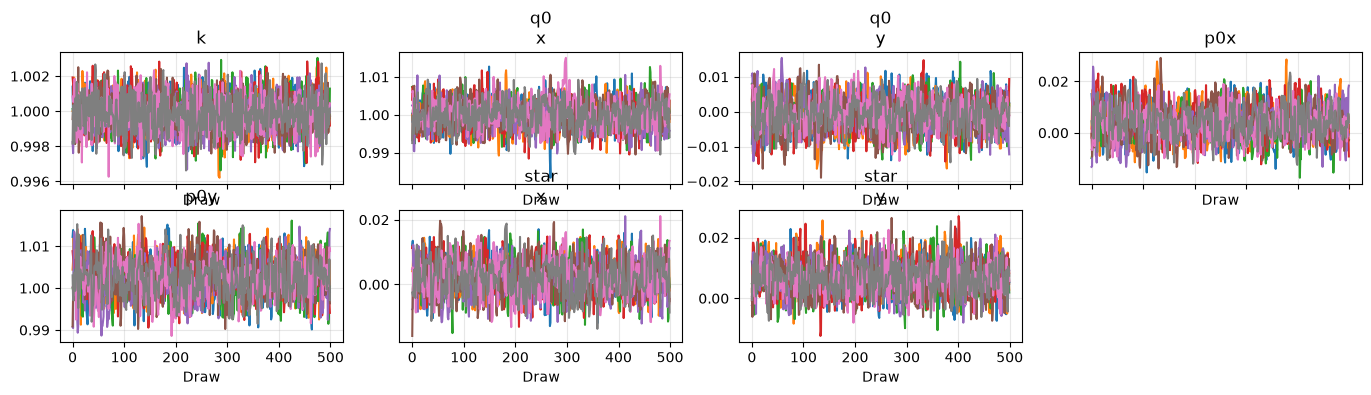

In [19]:
axes_pars = ["k", "q0", "p0x", "p0y", "star"]
az.plot_trace(idata_star1, var_names=axes_pars);

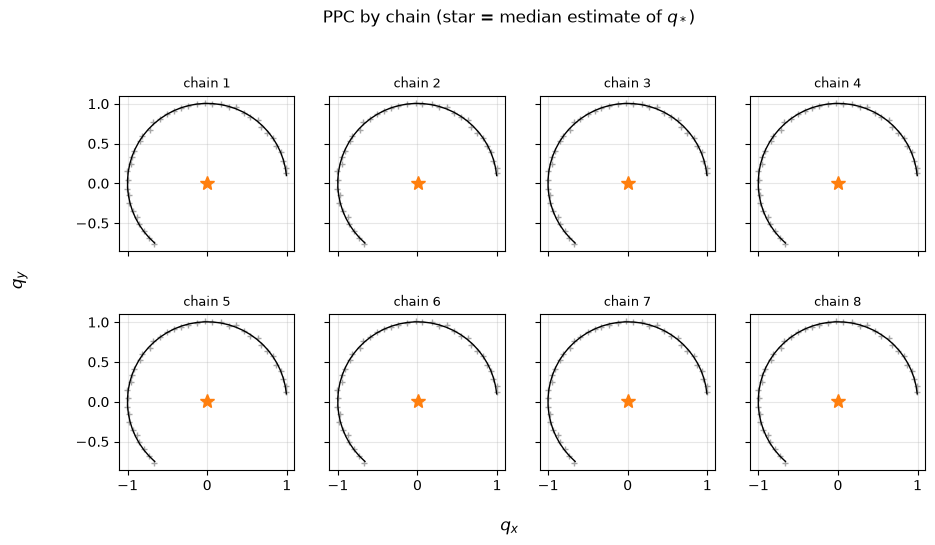

In [20]:
fig = ppc_plot_2d(idata_star1, q_obs, extra_var="star")
fig.suptitle("PPC by chain (star = median estimate of $q_*$)", y=1.02)
plt.show()

In [21]:
# チェーンごとの q0 と star の距離、および lp:
# 悪いチェーンの共通点は「q0 と star が非常に近い」こと (原典の観察)
q0_med = idata_star1.posterior["q0"].median(dim="draw").values
star_med = idata_star1.posterior["star"].median(dim="draw").values
pd.DataFrame({
    "|q0 - star|": np.linalg.norm(q0_med - star_med, axis=1),
    "mean lp": idata_star1.sample_stats["lp"].mean(dim="draw").values,
}, index=[f"chain {c+1}" for c in range(CHAINS)]).round(3)

,|q0 - star|,mean lp
chain 1,0.998,-245.174
chain 2,0.997,-245.373
chain 3,0.998,-245.484
chain 4,0.998,-245.238
chain 5,0.999,-245.206
chain 6,0.997,-245.116
chain 7,0.998,-245.330
chain 8,0.998,-245.445


原典では 8 チェーン中 5 本が正しい答えに収束し、3 本が別の領域に迷い込みました
(343/8000 の divergence と maximum treedepth 超過も報告されています)。
どのチェーンが悪くなるかは実装や乱数に依存しますが、悪いチェーンには共通の特徴があります:
**$q_0$ と $q_*$ が非常に近い**(惑星の初期位置が星のすぐそば)。
そして例によって、悪いチェーンは lp が低く、事後予測チェックで観測を再現できません。

### 8.3 条件付き尤度でモードを理解する (原典 §5.3)

今度はパラメータが 7 次元なので、$k$ のときのようなグリッド計算はできません。
そこで**条件付き尤度**を使います: 他のパラメータを(真値または良いチェーンの推定値に)固定し、
残りのパラメータを動かして尤度の断面を見る — これもまた「モデルの単純化」の一種です。

星の位置をずらすことは、惑星と星の距離 $r$ を通じて重力を強めたり弱めたりする操作であり、
$k$ をいじるのと似た病理(周回数の変化 → 偶然の整列 → 局所モード)が予想されます。

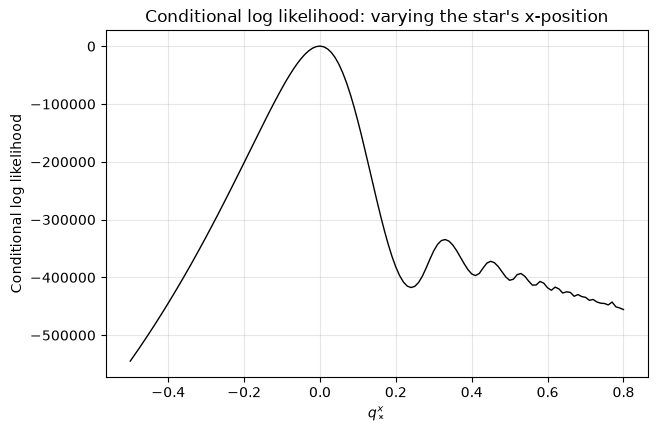

In [22]:
# 1D: star_x を動かす (他は真値に固定)
star_x_grid = np.arange(-0.5, 0.8 + 1e-9, 0.01)
stars_1d = np.column_stack([star_x_grid, np.zeros_like(star_x_grid)])
q_sim_1d = solve_trajectory_batch(np.ones(len(stars_1d)), q0_true, p0_true, star=stars_1d)
with np.errstate(all="ignore"):
    ll_1d = stats.norm.logpdf(q_obs[None], q_sim_1d, sigma_obs).sum(axis=(1, 2))

fig, ax = plt.subplots()
ax.plot(star_x_grid, ll_1d, "k-", lw=1)
ax.set_xlabel("$q_*^x$"); ax.set_ylabel("Conditional log likelihood")
ax.set_title("Conditional log likelihood: varying the star's x-position")
plt.show()

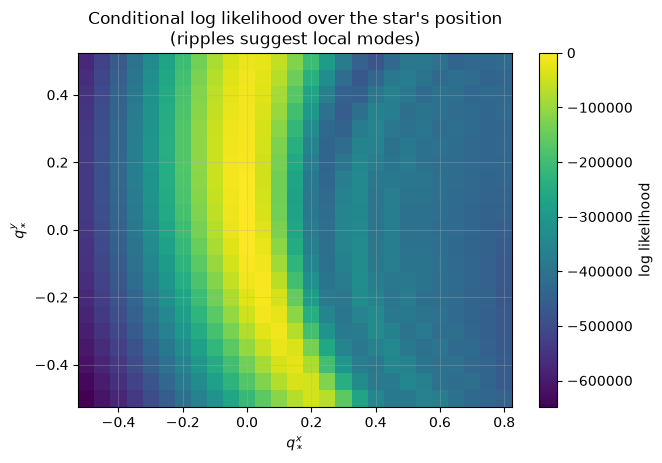

In [23]:
# 2D ヒートマップ: (star_x, star_y) を動かす
sx = np.arange(-0.5, 0.8 + 1e-9, 0.05)
sy = np.arange(-0.5, 0.5 + 1e-9, 0.05)
SX, SY = np.meshgrid(sx, sy)
stars_2d = np.column_stack([SX.ravel(), SY.ravel()])
q_sim_2d = solve_trajectory_batch(np.ones(len(stars_2d)), q0_true, p0_true, star=stars_2d)
with np.errstate(all="ignore"):
    ll_2d = stats.norm.logpdf(q_obs[None], q_sim_2d, sigma_obs).sum(axis=(1, 2))
ll_2d = ll_2d.reshape(SX.shape)

fig, ax = plt.subplots(figsize=(7, 4.6))
pc = ax.pcolormesh(SX, SY, np.where(np.isfinite(ll_2d), ll_2d, np.nan),
                   shading="auto", cmap="viridis")
fig.colorbar(pc, label="log likelihood")
ax.set_xlabel("$q_*^x$"); ax.set_ylabel("$q_*^y$")
ax.set_title("Conditional log likelihood over the star's position\n(ripples suggest local modes)")
plt.show()

1D の断面は期待どおりのプロファイル(真値 $q_*^x = 0$ に鋭いピーク + 裾のうねり)を示し、
2D のヒートマップには「さざ波」が見えます。lp・事後予測チェックと合わせて、
**これらのモードは前と同じ数学的人工物**であり、興味ある潜在現象ではないと判断できます。

### 8.4 事前分布と整合的な初期値で再フィット (原典 §5.4)

観測数が多く測定誤差が非常に小さいため、尤度(とその厄介なモード)が事後分布を支配します。
事前分布だけでは足りず、**より賢い初期値**で推定を助けます: 星の初期位置を事前分布
$\mathrm{Normal}(0, 0.5)$ から引き、$q_0, p_0$ の摂動も少し広げます(原典は $\mathrm{sd} = 0.5$)。

In [24]:
def init_empirical2(rng):
    p0_init = rng.normal(p0_empirical, 0.5)
    p0_init[1] = max(p0_init[1], 0.05)
    return {
        "k": float(abs(rng.normal(0, 1))) + 1e-3,
        "q0": rng.normal(q0_empirical, 0.5),
        "p0x": float(p0_init[0]),
        "p0y": float(p0_init[1]),
        "star": rng.normal(0, 0.5, 2),
    }


inits_pass2 = [init_empirical2(init_rng2) for _ in range(CHAINS)]

t0 = time.time()
idata_star2 = sample_jax_nuts(
    model=model_star, nuts_sampler="numpyro",
    draws=500, tune=500, chains=CHAINS,
    initvals=inits_pass2, jitter=False, chain_method="vectorized",
    random_seed=RANDOM_SEED, progressbar=False,
)
print(f"sampling took {time.time() - t0:.0f} s")
print(f"divergences: {int(idata_star2.sample_stats['diverging'].sum())}")

summ_star2 = az.summary(idata_star2, var_names=pars)
summ_star2[["mean", "sd", "ess_bulk", "ess_tail", "r_hat"]]

There were 81 divergences after tuning. Increase `target_accept` or reparameterize.


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


sampling took 1605 s
divergences: 81


,mean,sd,ess_bulk,ess_tail,r_hat
k,1.1,0.5,8,9,4.51
q0[x],0.9,0.5,8,9,4.00
q0[y],-0.1,0.3,8,9,4.16
p0[x],0.2,0.4,8,9,3.92
p0[y],0.7,0.5,8,9,3.96
star[x],0.1,0.26,8,9,3.96
star[y],-0.1,0.15,8,9,3.44


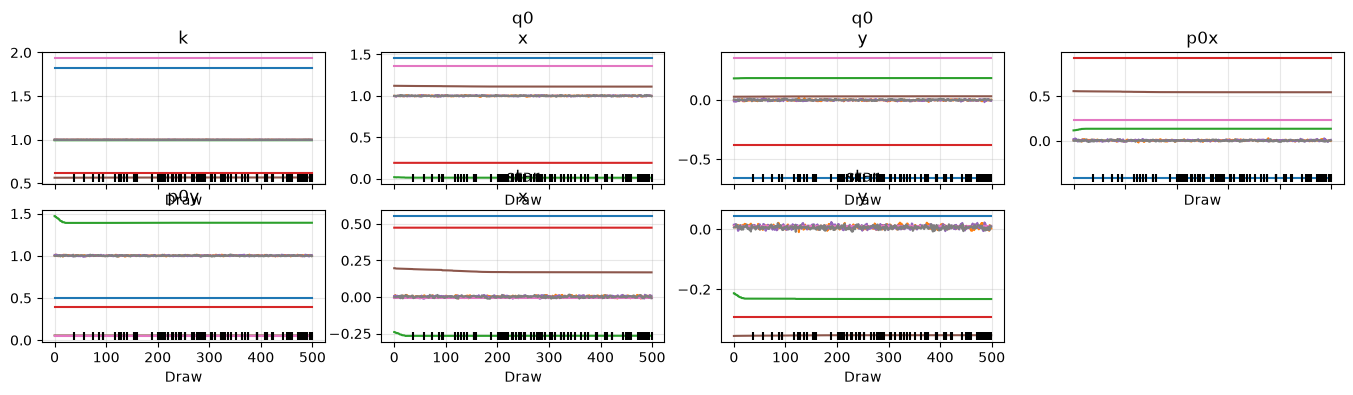

In [25]:
az.plot_trace(idata_star2, var_names=axes_pars);

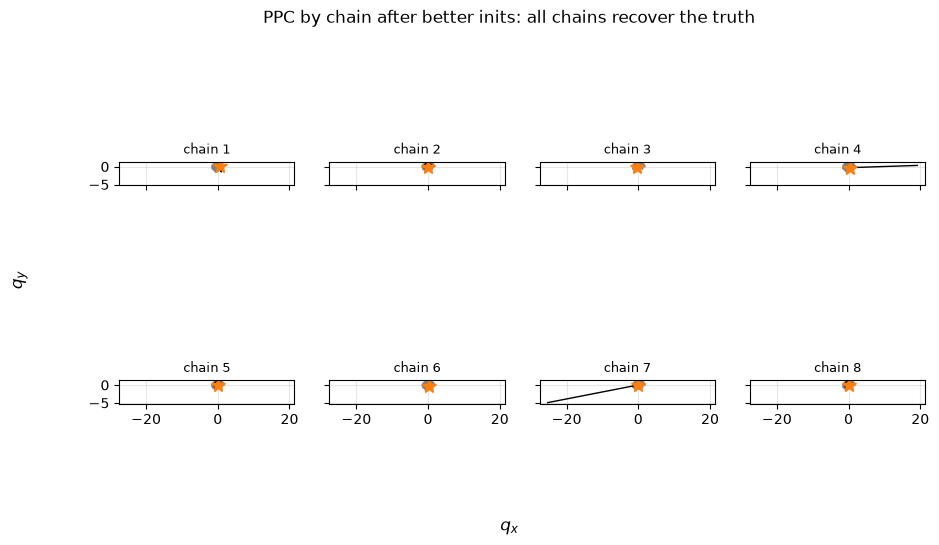

In [26]:
fig = ppc_plot_2d(idata_star2, q_obs, extra_var="star")
fig.suptitle("PPC by chain after better inits: all chains recover the truth", y=1.02)
plt.show()

In [27]:
# 真値との照合 (シミュレーションベースの検証):
truth = {"k": k_true, "q0[x]": q0_true[0], "q0[y]": q0_true[1],
         "p0[x]": p0_true[0], "p0[y]": p0_true[1],
         "star[x]": 0.0, "star[y]": 0.0}
post = idata_star2.posterior
est = {
    "k": post["k"], "q0[x]": post["q0"].sel(coord="x"), "q0[y]": post["q0"].sel(coord="y"),
    "p0[x]": post["p0"].sel(coord="x"), "p0[y]": post["p0"].sel(coord="y"),
    "star[x]": post["star"].sel(coord="x"), "star[y]": post["star"].sel(coord="y"),
}
rows = []
for name, da in est.items():
    lo, hi = np.percentile(da.values, [2.5, 97.5])
    rows.append({"parameter": name, "true": truth[name],
                 "post mean": float(da.mean()), "2.5%": lo, "97.5%": hi,
                 "in 95% CI": lo <= truth[name] <= hi})
pd.DataFrame(rows).round(4)

,parameter,true,post mean,2.5%,97.5%,in 95% CI
0,k,1.0,1.1181,0.5657,1.9381,True
1,q0[x],1.0,0.8918,0.0117,1.4579,True
2,q0[y],0.0,-0.0582,-0.6552,0.3543,True
3,p0[x],0.0,0.1799,-0.4135,0.9292,True
4,p0[y],1.0,0.6741,0.0500,1.3923,True
5,star[x],0.0,0.1171,-0.2656,0.5534,True
6,star[y],0.0,-0.1001,-0.3541,0.0439,True


全チェーンが一致し、$\widehat R \approx 1$、事後予測は観測を再現し、真値は事後区間に収まりました。
**すべての診断が「フィット成功」を支持**しています。

## 9. 議論と教訓 (原典 §6)

- **モデルのフィットに失敗したら、単純化したモデルを調べる**。うまい単純化とは「扱いやすいのに、理解したい病理を
  まだ示す」ものです。パラメータの固定はもっとも直接的な単純化です(階層モデルならより凝った単純化もありえます)
- **多峰性では、局所モードの発生機構と確率質量への寄与を理解することが重要**。ここでは事後予測チェックが決定打でした。
  無視できる質量しか持たない「くだらないモード」がチェーンを捕まえることは珍しくありません。
  だからこそ**複数チェーン**(場合によってはデフォルトの 4 本より多く)を走らせるべきです
- **初期値はチューニングパラメータである**。チェーンは漸近的には初期値を忘れるはずですが、有限のランでは忘れないことがある。
  万能のデフォルト事前分布がないのと同様に、万能のデフォルト初期値もありません。
  収束診断のためには過分散な初期値が欲しい一方、分散が大きすぎるとチェーンが妥当な領域に届かない。
  初期値の選択も、最初のフィットの観察を踏まえた反復的なプロセスになりえます
- **不良チェーンを無思慮に捨ててはいけない**。この例で初期値の調整が正当化されるのは、
  (a) デフォルト初期値が我々の専門知識と大きく矛盾していたこと、
  (b) 局所モードが(周期的データと正規尤度の相互作用という)興味のない人工物だと**詳細な分析で**示せたこと、
  の 2 点があるからです

### PyMC 実装のまとめ

| Stan | PyMC (本ノートブック) |
|---|---|
| `integrate_ode_rk45 / bdf`(適応刻み、感度方程式) | `pytensor.scan` による固定刻み RK4 + 自動微分 |
| `init = 0.5` 等(非制約空間の一様初期値) | `initvals=` にチェーンごとの辞書、`jitter=False` |
| `real<lower=0> k; k ~ normal(1, 0.001);` | `pm.TruncatedNormal("k", 1, 0.001, lower=0)` |
| `p0[2] ~ lognormal(0, 1);` | `pm.LogNormal("p0y", 0, 1)` |
| `generated quantities` の `q_pred` | `Deterministic("q")` + 観測ノイズ(保存済みの値から計算) |
| `lp__` | `idata.sample_stats["lp"]` |

### 参考文献

- Gelman, A. et al. (2020). Bayesian Workflow. [arXiv:2011.01808](https://arxiv.org/abs/2011.01808)(§11 に本例が登場)
- Margossian, C. C. and Gelman, A. Bayesian Model of Planetary Motion.
  [Stan Case Study](https://mc-stan.org/learn-stan/case-studies/planetary_motion.html)
- Betancourt, M. (2018). A Conceptual Introduction to Hamiltonian Monte Carlo. arXiv:1701.02434
- Yao, Y. et al. (2018). Using stacking to average Bayesian predictive distributions. *Bayesian Analysis*
- Vehtari, A. et al. (2021). Rank-normalization, folding, and localization: An improved $\widehat R$. *Bayesian Analysis*